# RoundaboutHD Data Cleaning & Preparation

## 1. Data Loading & Inspection

In [1]:
from pathlib import Path
import zipfile

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

# Run the notebook from the project folder.
PROJECT_DIR = Path.cwd()
ARCHIVE_PATH = PROJECT_DIR / "data" / "RoundaboutHD.zip"
OUT_DIR = PROJECT_DIR / "data" / "processed"
IMG_W, IMG_H = 3840, 2160

assert ARCHIVE_PATH.is_file(), "RoundaboutHD.zip should be in the project's data folder."

In [2]:
with zipfile.ZipFile(ARCHIVE_PATH) as archive:
    files = pd.DataFrame([
        {
            "path": item.filename,
            "extension": Path(item.filename).suffix.lower(),
            "size_mb": item.file_size / 1024**2,
        }
        for item in archive.infolist()
        if not item.is_dir()
    ])

pd.set_option("display.max_colwidth", 120)
display(files.head(30))

,path,extension,size_mb
0,RoundaboutHD/layout.jpg,.jpg,0.154351
1,RoundaboutHD/Multi_CAM_Ground_Turth.txt,.txt,7.552815
2,RoundaboutHD/Vehicle_statistic.xlsx,.xlsx,0.040157
3,RoundaboutHD/README.md,.md,0.002734
4,RoundaboutHD/RoundaboutHD_Reid_subset/test_images/0654_cam02_000817.jpg,.jpg,0.005427
5,RoundaboutHD/RoundaboutHD_Reid_subset/test_images/0655_cam03_001901.jpg,.jpg,0.005135
6,RoundaboutHD/RoundaboutHD_Reid_subset/test_images/0655_cam04_002575.jpg,.jpg,0.003654
7,RoundaboutHD/RoundaboutHD_Reid_subset/test_images/0655_cam04_002600.jpg,.jpg,0.002621
8,RoundaboutHD/RoundaboutHD_Reid_subset/test_images/0004_cam01_000263.jpg,.jpg,0.028073
9,RoundaboutHD/RoundaboutHD_Reid_subset/test_images/0004_cam01_000368.jpg,.jpg,0.005314


In [3]:
display(
    files.groupby("extension")
    .agg(file_count=("path", "size"), total_size_mb=("size_mb", "sum"))
    .sort_values("total_size_mb", ascending=False)
    .round(2)
)
display(files.loc[files["extension"].isin([".txt", ".csv", ".xlsx", ".md"])])

,file_count,total_size_mb
extension,,
.mp4,4,6569.14
.jpg,65527,1094.90
.zip,12,44.82
.txt,5,16.51
.png,8,2.83
.xlsx,1,0.04
.yaml,4,0.02
.md,1,0.00
.json,4,0.00


,path,extension,size_mb
1,RoundaboutHD/Multi_CAM_Ground_Turth.txt,.txt,7.552815
2,RoundaboutHD/Vehicle_statistic.xlsx,.xlsx,0.040157
3,RoundaboutHD/README.md,.md,0.002734
65534,RoundaboutHD/imagesc001/SCT/SCT_GT.txt,.txt,2.372145
65545,RoundaboutHD/imagesc002/SCT/SCT_GT.txt,.txt,2.108500
65555,RoundaboutHD/imagesc003/SCT/SCT_GT.txt,.txt,2.284753
65565,RoundaboutHD/imagesc004/SCT/SCT_GT.txt,.txt,2.195249


In [4]:
ground_truth_files = files.loc[
    files["path"].map(
        lambda name: Path(name).name.lower()
        in {"multi_cam_ground_turth.txt", "multi_cam_ground_truth.txt"}
    ),
    "path",
].tolist()

if len(ground_truth_files) != 1:
    raise ValueError(f"Expected one annotation file: {ground_truth_files}")

with zipfile.ZipFile(ARCHIVE_PATH) as archive:
    with archive.open(ground_truth_files[0]) as source:
        for _ in range(5):
            print(source.readline().decode("utf-8").rstrip())

1 645 123 2310.00 89.00 39.00 27.00 -1 -1
1 645 124 2310.80 88.20 36.60 28.60 -1 -1
1 645 125 2310.17 87.29 36.13 31.17 -1 -1
1 645 126 2308.39 89.18 35.98 29.14 -1 -1
1 645 127 2305.60 90.66 38.22 29.04 -1 -1


In [5]:
columns = [
    "camera_id", "vehicle_id", "frame",
    "x", "y", "width", "height",
    "xworld", "yworld",
]

with zipfile.ZipFile(ARCHIVE_PATH) as archive:
    with archive.open(ground_truth_files[0]) as source:
        df = pd.read_csv(source, sep=r"\s+", header=None)

if df.shape[1] != len(columns):
    raise ValueError(f"Expected {len(columns)} columns, found {df.shape[1]}")

df.columns = columns
print(f"Rows: {df.shape[0]:,}; columns: {df.shape[1]}")
display(df.head(10))
df.info()

Rows: 177,782; columns: 9


,camera_id,vehicle_id,frame,x,y,width,height,xworld,yworld
0,1,645,123,2310.00,89.00,39.00,27.00,-1,-1
1,1,645,124,2310.80,88.20,36.60,28.60,-1,-1
2,1,645,125,2310.17,87.29,36.13,31.17,-1,-1
3,1,645,126,2308.39,89.18,35.98,29.14,-1,-1
4,1,645,127,2305.60,90.66,38.22,29.04,-1,-1
5,1,645,128,2304.73,91.11,36.83,30.45,-1,-1
6,1,645,129,2302.40,91.93,37.69,30.24,-1,-1
7,1,645,130,2300.26,92.88,38.67,30.14,-1,-1
8,1,645,131,2298.87,93.88,38.35,29.42,-1,-1
9,1,645,132,2297.76,94.21,36.85,29.82,-1,-1


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 177782 entries, 0 to 177781
Data columns (total 9 columns):
 #   Column      Non-Null Count   Dtype  
---  ------      --------------   -----  
 0   camera_id   177782 non-null  int64  
 1   vehicle_id  177782 non-null  int64  
 2   frame       177782 non-null  int64  
 3   x           177782 non-null  float64
 4   y           177782 non-null  float64
 5   width       177782 non-null  float64
 6   height      177782 non-null  float64
 7   xworld      177782 non-null  int64  
 8   yworld      177782 non-null  int64  
dtypes: float64(4), int64(5)
memory usage: 12.2 MB


In [6]:
excel_files = files.loc[files["extension"].eq(".xlsx"), "path"].tolist()

with zipfile.ZipFile(ARCHIVE_PATH) as archive:
    for name in excel_files:
        with archive.open(name) as source:
            with pd.ExcelFile(source, engine="openpyxl") as workbook:
                for sheet in workbook.sheet_names:
                    print(f"{name} | {sheet}")
                    display(pd.read_excel(workbook, sheet_name=sheet, nrows=10))

RoundaboutHD/Vehicle_statistic.xlsx | imagesc001


,Number,Colour,Make,Model,Note,Category,Unnamed: 6,Unnamed: 7,Unnamed: 8,SUV and Offroaders
0,1,Dark Blue,Hyundai,Sonata,NaN,Small Passenger Vehicles,NaN,NaN,NaN,People Carriers and MPV
1,5,White,Toyota,Camry,NaN,Small Passenger Vehicles,NaN,NaN,NaN,Pick Up
2,13,Black,Chevrolet,Malibu,NaN,Small Passenger Vehicles,NaN,NaN,NaN,Commercial Van
3,14,Silver,Toyota,RAV4,NaN,SUV and Offroaders,NaN,NaN,NaN,Heavy Duty Trucks
4,15,Green,Peterbilt,Vehicle Transporter,NaN,Heavy Duty Trucks,NaN,NaN,NaN,Small Passenger Vehicles
5,17,White,Chevrolet,Express,With ticket,Commercial Van,NaN,NaN,NaN,NaN
6,19,Black,Lexus,RX,NaN,SUV and Offroaders,NaN,NaN,NaN,NaN
7,22,Black,Mercedes,C Class,W204,Small Passenger Vehicles,NaN,NaN,NaN,NaN
8,25,Silver,Hyundai,Tucson,"also 42, two id due to serval occlusion",SUV and Offroaders,NaN,NaN,NaN,NaN
9,27,Blue,Honda,Fit,NaN,Small Passenger Vehicles,NaN,NaN,NaN,NaN


RoundaboutHD/Vehicle_statistic.xlsx | imagesc002


,Number,Colour,Make,Model,Note,Category,Unnamed: 6,SUV and Offroaders
0,1,Grey,Dodge,Ram,NaN,Pick Up,NaN,People Carriers and MPV
1,2,Red,Concrete,Mixer,NaN,Heavy Duty Trucks,NaN,Pick Up
2,3,White,Chevrolet,Silverado,NaN,Pick Up,NaN,Commercial Van
3,4,White,Ford,Transit,NaN,Commercial Van,NaN,Heavy Duty Trucks
4,10,Silver,Tesla,Model 3,NaN,Small Passenger Vehicles,NaN,Small Passenger Vehicles
5,13,White,GMC,Yukon,NaN,SUV and Offroaders,NaN,NaN
6,14,Red,Buick,Enclave,NaN,SUV and Offroaders,NaN,NaN
7,15,Black,Honda,Accord,NaN,Small Passenger Vehicles,NaN,NaN
8,17,Black,GMC,Terrain,NaN,SUV and Offroaders,NaN,NaN
9,19,Dark Blue,Kia,Sorento,NaN,SUV and Offroaders,NaN,NaN


RoundaboutHD/Vehicle_statistic.xlsx | imagesc003


,Number,Colour,Make,Model,Note,Category,Unnamed: 6,Unnamed: 7
0,1,White Blue Black,Honda,CRV,NaN,SUV and Offroaders,NaN,SUV and Offroaders
1,2,Grey,Toyota,Highlander,NaN,SUV and Offroaders,NaN,People Carriers and MPV
2,3,Black,Toyota,Highlander,NaN,SUV and Offroaders,NaN,Pick Up
3,7,NaN,NaN,NaN,NaN,Small Passenger Vehicles,NaN,NaN
4,11,Silver,Subaru,Outback,NaN,SUV and Offroaders,NaN,Commercial Van
5,14,Black,Lexus,ES,NaN,Small Passenger Vehicles,NaN,Heavy Duty Trucks
6,16,Brown,BMW,3 series,NaN,Small Passenger Vehicles,NaN,Small Passenger Vehicles
7,18,Red,MACK,Truck,NaN,Heavy Duty Trucks,NaN,NaN
8,21,White,Chevrolet,Silverado,NaN,Pick Up,NaN,NaN
9,22,Black,Chevrolet,Equinox,NaN,SUV and Offroaders,NaN,NaN


RoundaboutHD/Vehicle_statistic.xlsx | imagesc004


,Number,Colour,Make,Model,Note,Category,Unnamed: 6,Unnamed: 7
0,1,White,Ford,F150,NaN,Pick Up,NaN,SUV and Offroaders
1,2,Black,Cadillac,Escalade,NaN,SUV and Offroaders,NaN,People Carriers and MPV
2,3,Dark Red,Dodge,RAM,NaN,Pick Up,NaN,Pick Up
3,5,Black,Nissan,Maxima,NaN,Small Passenger Vehicles,NaN,Commercial Van
4,7,Silver,Chrysler,Pacifica,NaN,People Carriers and MPV,NaN,Heavy Duty Trucks
5,8,Grey,Toyota,RAV4,NaN,SUV and Offroaders,NaN,Small Passenger Vehicles
6,9,Red,Buick,Enclave,NaN,SUV and Offroaders,NaN,NaN
7,10,Dark Blue,Hyundai,Santa Fe,NaN,SUV and Offroaders,NaN,NaN
8,12,Black,Chevrolet,Impala,NaN,Small Passenger Vehicles,NaN,NaN
9,14,Dark Blue,Ford,Mustang,NaN,Small Passenger Vehicles,NaN,NaN


In [7]:
with zipfile.ZipFile(ARCHIVE_PATH) as archive:
    with archive.open("RoundaboutHD/Vehicle_statistic.xlsx") as source:
        vehicle_sheets = pd.read_excel(source, sheet_name=None)

vehicle_columns = ["Number", "Colour", "Make", "Model", "Category"]
vehicle_tables = []

for sheet_name, table in vehicle_sheets.items():
    table = table.loc[:, vehicle_columns].copy()
    for column in vehicle_columns[1:]:
        table[column] = table[column].astype("string").str.strip().replace("", pd.NA)
    table.insert(0, "camera_id", int(sheet_name.removeprefix("imagesc")))
    vehicle_tables.append(table)

vehicles = pd.concat(vehicle_tables, ignore_index=True)
display(vehicles.head(10))

,camera_id,Number,Colour,Make,Model,Category
0,1,1,Dark Blue,Hyundai,Sonata,Small Passenger Vehicles
1,1,5,White,Toyota,Camry,Small Passenger Vehicles
2,1,13,Black,Chevrolet,Malibu,Small Passenger Vehicles
3,1,14,Silver,Toyota,RAV4,SUV and Offroaders
4,1,15,Green,Peterbilt,Vehicle Transporter,Heavy Duty Trucks
5,1,17,White,Chevrolet,Express,Commercial Van
6,1,19,Black,Lexus,RX,SUV and Offroaders
7,1,22,Black,Mercedes,C Class,Small Passenger Vehicles
8,1,25,Silver,Hyundai,Tucson,SUV and Offroaders
9,1,27,Blue,Honda,Fit,Small Passenger Vehicles


In [8]:
sct_tables = []
with zipfile.ZipFile(ARCHIVE_PATH) as archive:
    for cam in range(1, 5):
        with archive.open(f"RoundaboutHD/imagesc{cam:03d}/SCT/SCT_GT.txt") as source:
            t = pd.read_csv(source, sep=r"\s+", header=None,
                            names=["frame", "track_id", "x1", "y1", "x2", "y2", "cls"])
        t.insert(0, "camera_id", cam)
        sct_tables.append(t)

sct_raw = pd.concat(sct_tables, ignore_index=True)
assert sct_raw["cls"].nunique() == 1
sct_raw = sct_raw.assign(x=sct_raw.x1, y=sct_raw.y1, width=sct_raw.x2 - sct_raw.x1, height=sct_raw.y2 - sct_raw.y1)
sct_raw = sct_raw.drop(columns=["x1", "y1", "x2", "y2", "cls"])

display(sct_raw.head())

,camera_id,frame,track_id,x,y,width,height
0,1,1,1,299.00,1118.00,588.00,444.00
1,1,2,1,352.80,1086.76,580.19,424.04
2,1,3,1,409.82,1057.61,570.23,407.94
3,1,4,1,469.57,1025.30,561.91,389.45
4,1,5,1,528.16,991.50,552.91,378.44


### Initial Data Quality Checks

Check missing vehicle attributes, invalid bounding boxes and repeated observation keys. The box issue counts can overlap; incomplete attribute records are retained.

In [9]:
missing_mask = vehicles[vehicle_columns].isna().any(axis=1)
display(vehicles.loc[missing_mask])
display(vehicles[vehicle_columns].isna().sum().to_frame("missing_values"))
print(f"Original rows: {len(vehicles)}")
print(f"Complete rows: {(~missing_mask).sum()}")
print(f"Incomplete rows retained: {missing_mask.sum()}")

,camera_id,Number,Colour,Make,Model,Category
74,1,161,Black,Chevrolet,Silverado,<NA>
283,2,38,Grey,Nissan,<NA>,SUV and Offroaders
509,3,7,<NA>,<NA>,<NA>,Small Passenger Vehicles
776,3,509,<NA>,<NA>,<NA>,SUV and Offroaders


,missing_values
Number,0
Colour,2
Make,2
Model,3
Category,1


Original rows: 1042
Complete rows: 1038
Incomplete rows retained: 4


In [10]:
box_quality = []
for name, table, key in [
    ("MTMC", df, ["camera_id", "vehicle_id", "frame"]),
    ("SCT", sct_raw, ["camera_id", "track_id", "frame"])
]:
    boxes = table[["x", "y", "width", "height"]]
    box_quality.append({
        "dataset": name,
        "rows": len(table),
        "non_finite_boxes": (~np.isfinite(boxes).all(axis=1)).sum(),
        "non_positive_boxes": ((table["width"] <= 0) | (table["height"] <= 0)).sum(),
        "outside_image": (
            (table["x"] < 0) | (table["y"] < 0) |
            (table["x"] + table["width"] > IMG_W) |
            (table["y"] + table["height"] > IMG_H)
        ).sum(),
        "duplicate_observations": table.duplicated(key).sum()
    })

display(pd.DataFrame(box_quality).set_index("dataset"))

,rows,non_finite_boxes,non_positive_boxes,outside_image,duplicate_observations
dataset,,,,,
MTMC,177782,0,0,673,26
SCT,232945,0,0,748,26


## 2. Data Cleaning

In [11]:
def clip_boxes(frame, x="x", y="y", w="width", h="height"):
    valid = (
        np.isfinite(frame[[x, y, w, h]]).all(axis=1) &
        (frame[w] > 0) & (frame[h] > 0)
    )
    frame = frame.loc[valid].copy()
    x2 = (frame[x] + frame[w]).clip(upper=IMG_W)
    y2 = (frame[y] + frame[h]).clip(upper=IMG_H)
    frame[x] = frame[x].clip(lower=0)
    frame[y] = frame[y].clip(lower=0)
    frame[w] = x2 - frame[x]
    frame[h] = y2 - frame[y]
    return frame.loc[(frame[w] > 0) & (frame[h] > 0)].copy()


def keep_largest_box(frame, key):
    area = frame["width"] * frame["height"]
    return (
        frame.assign(_area=area)
        .sort_values("_area", ascending=False, kind="stable")
        .drop_duplicates(key)
        .drop(columns="_area")
    )

### Multi-camera ground truth

In [12]:
assert (df[["xworld", "yworld"]] == -1).all().all()
mtmc = df.drop(columns=["xworld", "yworld"]).copy()

n0 = len(mtmc)
mtmc = clip_boxes(mtmc)
n_valid = len(mtmc)
mtmc = keep_largest_box(mtmc, ["camera_id", "vehicle_id", "frame"])
mtmc = mtmc.sort_values(["camera_id", "frame", "vehicle_id"]).reset_index(drop=True)

print(f"Rows: {n0:,} -> {len(mtmc):,}")
print(f"Invalid boxes removed: {n0 - n_valid:,}")
print(f"Duplicate observations removed: {n_valid - len(mtmc):,}")
print("Cameras per vehicle:", mtmc.groupby("vehicle_id")["camera_id"].nunique().value_counts().sort_index().to_dict())

Rows: 177,782 -> 177,756
Invalid boxes removed: 0
Duplicate observations removed: 26
Cameras per vehicle: {1: 6, 2: 162, 3: 69, 4: 74}


### Single-camera ground truth

In [13]:
sct = sct_raw.copy()

n0 = len(sct)
sct = clip_boxes(sct)
n_valid = len(sct)
sct = keep_largest_box(sct, ["camera_id", "track_id", "frame"])
sct = sct.sort_values(["camera_id", "frame", "track_id"]).reset_index(drop=True)

print(f"Rows: {n0:,} -> {len(sct):,}")
print(f"Invalid boxes removed: {n0 - n_valid:,}")
print(f"Duplicate observations removed: {n_valid - len(sct):,}")
display(sct.groupby("camera_id").agg(rows=("frame", "size"), tracks=("track_id", "nunique")))

Rows: 232,945 -> 232,919
Invalid boxes removed: 0
Duplicate observations removed: 26


,rows,tracks
camera_id,,
1,61709,262
2,54686,244
3,59806,279
4,56718,257


### Vehicle attributes

In [14]:
COLOUR_FIX = {"white": "White", "Gold": "Golden", "Yellow Red": "Red/Yellow"}
MAKE_FIX = {"KIA": "Kia", "MACK": "Mack", "Mistubushi": "Mitsubishi", "Cadliac": "Cadillac", "Range": "Land Rover"}
MODEL_FIX = {
    "Odessey": "Odyssey", "Carolla": "Corolla", "Cheerokee": "Cherokee",
    "Grand Cheerokee": "Grand Cherokee", "Equinix": "Equinox", "C Classs": "C Class",
    "k5": "K5", "F150": "F-150", "Ram": "RAM", "RIO": "Rio", "F-pace": "F-Pace",
    "Kick": "Kicks", "Transverse": "Traverse", "Branco": "Bronco", "Casdania": "Cascadia",
    "Altas Cross": "Atlas Cross Sport", "Rover Sport": "Range Rover Sport",
    "Vehicle transporter": "Vehicle Transporter", "vehicle transporter": "Vehicle Transporter",
}

attr_columns = ["Number", "Colour", "Make", "Model", "Category", "Note"]
attrs = pd.concat(
    [t[attr_columns].assign(camera_id=int(name.removeprefix("imagesc")))
     for name, t in vehicle_sheets.items()],
    ignore_index=True,
).rename(columns=str.lower).rename(columns={"number": "track_id", "colour": "color"})

attribute_cols = ["color", "make", "model", "category"]
original_cols = [f"{col}_original" for col in attribute_cols + ["note"]]
attrs[original_cols] = attrs[attribute_cols + ["note"]].copy()

for col in attribute_cols + ["note"]:
    attrs[col] = attrs[col].astype("string").str.strip().replace("", pd.NA)
attrs["color"] = attrs["color"].replace(COLOUR_FIX)
attrs["make"] = attrs["make"].replace(MAKE_FIX)
attrs["model"] = attrs["model"].replace(MODEL_FIX)
attrs["track_id"] = attrs["track_id"].astype(int)

# "also 42, two id due to occlusion" -> same vehicle split into two SCT tracks
attrs["linked_track_id"] = (
    attrs["note"].str.extract(r"(?i)also\s+(\d+)", expand=False).astype("Int64")
)
attrs["is_complete"] = attrs[attribute_cols].notna().all(axis=1)
attrs = attrs[["camera_id", "track_id", "color", "make", "model", "category",
               "linked_track_id", "is_complete", "note"] + original_cols]

assert not attrs.duplicated(["camera_id", "track_id"]).any()
display(attrs.loc[~attrs["is_complete"] | attrs["linked_track_id"].notna()])
print(attrs["category"].value_counts(dropna=False))

,camera_id,track_id,color,make,model,category,linked_track_id,is_complete,note,color_original,make_original,model_original,category_original,note_original
8,1,25,Silver,Hyundai,Tucson,SUV and Offroaders,42,True,"also 42, two id due to serval occlusion",Silver,Hyundai,Tucson,SUV and Offroaders,"also 42, two id due to serval occlusion"
13,1,42,Silver,Hyundai,Tucson,SUV and Offroaders,25,True,"also 25, two id due to serval occlusion",Silver,Hyundai,Tucson,SUV and Offroaders,"also 25, two id due to serval occlusion"
74,1,161,Black,Chevrolet,Silverado,<NA>,168,False,"Also 168, two id due to heavy occlusion",Black,Chevrolet,Silverado,NaN,"Also 168, two id due to heavy occlusion"
80,1,168,Black,Chevrolet,Silverado,Pick Up,161,True,"Also 161, two id due to heavy occlusion",Black,Chevrolet,Silverado,Pick Up,"Also 161, two id due to heavy occlusion"
283,2,38,Grey,Nissan,<NA>,SUV and Offroaders,<NA>,False,<NA>,Grey,Nissan,NaN,SUV and Offroaders,NaN
485,2,361,Black,Chevrolet,Traverse,SUV and Offroaders,364,True,"also 364, two id due to serval occlusion",Black,Chevrolet,Transverse,SUV and Offroaders,"also 364, two id due to serval occlusion"
487,2,364,Black,Chevrolet,Traverse,SUV and Offroaders,361,True,"also 361, two id due to serval occlusion",Black,Chevrolet,Transverse,SUV and Offroaders,"also 361, two id due to serval occlusion"
509,3,7,<NA>,<NA>,<NA>,Small Passenger Vehicles,<NA>,False,<NA>,NaN,NaN,NaN,Small Passenger Vehicles,NaN
776,3,509,<NA>,<NA>,<NA>,SUV and Offroaders,<NA>,False,<NA>,NaN,NaN,NaN,SUV and Offroaders,NaN
923,4,188,Black,Kia,K5,Small Passenger Vehicles,201,True,"also 201, two id due to serval occlusion",Black,KIA,K5,Small Passenger Vehicles,"also 201, two id due to serval occlusion"


category
SUV and Offroaders          475
Small Passenger Vehicles    288
Pick Up                     114
Heavy Duty Trucks            56
Commercial Van               55
People Carriers and MPV      53
<NA>                          1
Name: count, dtype: Int64


## 3. SCT-to-MTMC Matching

Candidate matches use IoU > 0.5 in the same camera and frame. Candidates are ranked by matched frames, then mean IoU. Ties use the smaller vehicle ID for reproducibility.

In [15]:
pairs = mtmc.merge(sct, on=["camera_id", "frame"], suffixes=("_g", "_s"))
ix = (np.minimum(pairs.x_g + pairs.width_g, pairs.x_s + pairs.width_s)
      - np.maximum(pairs.x_g, pairs.x_s)).clip(lower=0)
iy = (np.minimum(pairs.y_g + pairs.height_g, pairs.y_s + pairs.height_s)
      - np.maximum(pairs.y_g, pairs.y_s)).clip(lower=0)
inter = ix * iy
pairs["iou"] = inter / (pairs.width_g * pairs.height_g + pairs.width_s * pairs.height_s - inter)

In [16]:
match_quality = (
    pairs.loc[pairs["iou"] > 0.5]
    .groupby(["camera_id", "track_id", "vehicle_id"])
    .agg(
        matched_frames=("frame", "nunique"),
        mean_iou=("iou", "mean")
    )
    .reset_index()
    .sort_values(
        ["camera_id", "track_id", "matched_frames", "mean_iou", "vehicle_id"],
        ascending=[True, True, False, False, True]
    )
)

# Compare the best and second-best candidate
match_quality["rank"] = (
    match_quality.groupby(["camera_id", "track_id"])
    .cumcount() + 1
)

best = match_quality[match_quality["rank"] == 1].copy()

second = (
    match_quality[match_quality["rank"] == 2]
    [["camera_id", "track_id", "matched_frames"]]
    .rename(columns={"matched_frames": "second_best_frames"})
)

best = best.merge(
    second,
    on=["camera_id", "track_id"],
    how="left",
    validate="one_to_one"
)

best["second_best_frames"] = (
    best["second_best_frames"].fillna(0).astype(int)
)

best["confidence_gap"] = (
    best["matched_frames"] - best["second_best_frames"]
)

## 4. Mapping Rate by Camera

The initial mapping rate counts tracks with an IoU candidate, before acceptance checks. The chart uses this rate for comparison with the initially unmapped tracks.

In [17]:
total_tracks = sct[["camera_id", "track_id"]].drop_duplicates()
mapping_check = total_tracks.merge(
    best[["camera_id", "track_id"]].assign(is_mapped=True),
    on=["camera_id", "track_id"],
    how="left",
    validate="one_to_one"
)
mapping_check["is_mapped"] = mapping_check["is_mapped"].eq(True)

print("Total SCT tracks:", len(total_tracks))
print("Initial matches:", mapping_check["is_mapped"].sum())
print("Initially unmapped tracks:", (~mapping_check["is_mapped"]).sum())

camera_mapping = mapping_check.groupby("camera_id").agg(
    total_tracks=("track_id", "size"),
    mapped_tracks=("is_mapped", "sum"),
    mapping_rate=("is_mapped", "mean")
)
camera_mapping["unmapped_tracks"] = camera_mapping["total_tracks"] - camera_mapping["mapped_tracks"]
display(camera_mapping)

Total SCT tracks: 1042
Initial matches: 837
Initially unmapped tracks: 205


,total_tracks,mapped_tracks,mapping_rate,unmapped_tracks
camera_id,,,,
1,262,179,0.683206,83
2,244,222,0.909836,22
3,279,245,0.878136,34
4,257,191,0.743191,66


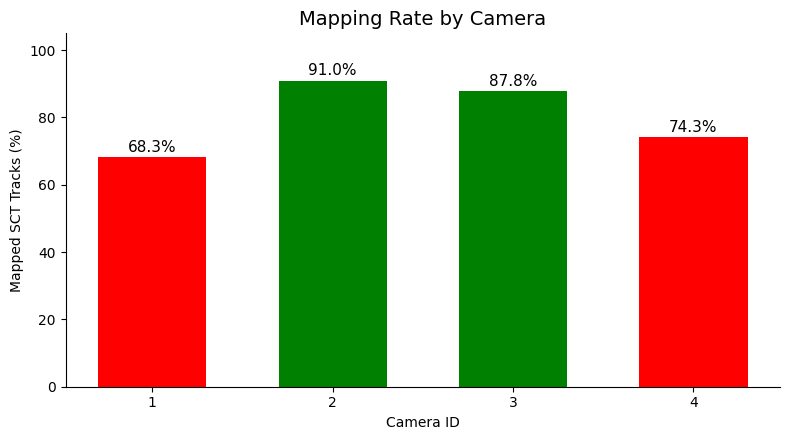

In [18]:
fig, ax = plt.subplots(figsize=(8, 4.5))

bars = ax.bar(
    camera_mapping.index.astype(str),
    camera_mapping["mapping_rate"] * 100,
    color=["green" if rate >= 0.80 else "red" for rate in camera_mapping["mapping_rate"]],
    width=0.6
)

for bar in bars:
    height = bar.get_height()
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        height + 1.5,
        f"{height:.1f}%",
        ha="center",
        fontsize=11
    )

ax.set_title("Mapping Rate by Camera", fontsize=14)
ax.set_xlabel("Camera ID")
ax.set_ylabel("Mapped SCT Tracks (%)")
ax.set_ylim(0, 105)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

plt.tight_layout()
(PROJECT_DIR / "figures").mkdir(exist_ok=True)
plt.savefig(PROJECT_DIR / "figures" / "mapping_rate_by_camera.png", dpi=150, bbox_inches="tight")
plt.show()

## 5. Matching Quality Assessment

Candidates need at least 3 matched frames and mean IoU >= 0.7 for acceptance. These thresholds, including candidate IoU > 0.5, are provisional project choices. Also check whether different SCT tracks receive the same global ID in the same camera and frame.

In [19]:
display(best[[
    "matched_frames", "mean_iou", "confidence_gap"
]].describe())

print("Matches with <= 2 frames:",
      (best["matched_frames"] <= 2).sum())

print("Ambiguous matches (gap <= 2):",
      (best["confidence_gap"] <= 2).sum())

,matched_frames,mean_iou,confidence_gap
count,837.000000,837.000000,837.000000
mean,212.187575,0.998636,211.986858
std,73.074580,0.023049,73.350692
min,1.000000,0.518919,1.000000
25%,176.000000,1.000000,176.000000
50%,204.000000,1.000000,204.000000
75%,238.000000,1.000000,238.000000
max,605.000000,1.000000,605.000000


Matches with <= 2 frames: 1
Ambiguous matches (gap <= 2): 1


In [20]:
best["match_status"] = "accepted"

low_confidence = (
    (best["matched_frames"] < 3) |
    (best["mean_iou"] < 0.7)
)

best.loc[low_confidence, "match_status"] = "review"

best["review_reason"] = pd.Series(pd.NA, index=best.index, dtype="string")
best.loc[low_confidence, "review_reason"] = "low_confidence"

In [21]:
accepted_candidates = best.loc[
    best["match_status"].eq("accepted"),
    ["camera_id", "track_id", "vehicle_id"]
]
shared_matches = accepted_candidates.loc[
    accepted_candidates.duplicated(["camera_id", "vehicle_id"], keep=False)
]

shared_track_details = shared_matches.merge(
    sct.groupby(["camera_id", "track_id"])
    .agg(first_frame=("frame", "min"), last_frame=("frame", "max"))
    .reset_index(),
    on=["camera_id", "track_id"],
    validate="one_to_one"
).merge(
    attrs[["camera_id", "track_id", "linked_track_id", "note"] + attribute_cols],
    on=["camera_id", "track_id"],
    how="left",
    validate="one_to_one"
)
display(shared_track_details)

shared_observations = sct[["camera_id", "track_id", "frame"]].merge(
    shared_matches,
    on=["camera_id", "track_id"],
    validate="many_to_one"
)
simultaneous_assignments = shared_observations.loc[
    shared_observations.duplicated(["camera_id", "vehicle_id", "frame"], keep=False)
]
display(
    simultaneous_assignments.groupby(["camera_id", "vehicle_id", "frame"])
    .agg(track_ids=("track_id", list))
)

conflict_tracks = simultaneous_assignments[["camera_id", "track_id"]].drop_duplicates()
best = best.merge(
    conflict_tracks.assign(mapping_conflict=True),
    on=["camera_id", "track_id"],
    how="left",
    validate="one_to_one"
)
best["mapping_conflict"] = best["mapping_conflict"].eq(True)
best.loc[best["mapping_conflict"], "match_status"] = "review"
best.loc[best["mapping_conflict"], "review_reason"] = "simultaneous_tracks"

,camera_id,track_id,vehicle_id,first_frame,last_frame,linked_track_id,note,color,make,model,category
0,3,29,553,339,599,<NA>,<NA>,White,Freightliner,Sweeper,Heavy Duty Trucks
1,3,78,644,1117,1287,<NA>,<NA>,Red,Freightliner,Truck,Heavy Duty Trucks
2,3,86,644,1134,1486,<NA>,<NA>,Brown,Kia,Sorento,SUV and Offroaders
3,3,293,553,5378,5689,<NA>,<NA>,Silver,Subaru,Outback,SUV and Offroaders


track_ids
camera_id vehicle_id frame          
3         644        1134   [78, 86]
                     1135   [78, 86]
                     1136   [78, 86]
                     1137   [78, 86]
                     1138   [78, 86]
                     1139   [78, 86]

### Shared Global IDs Within a Camera

Camera 3 tracks 78 and 86 both map to global ID 644. They overlap in six frames (1134–1139), occupy different positions, and have different vehicle annotations. Both assignments are flagged as `review`; the available evidence does not justify choosing one automatically.

Camera 3 tracks 29 and 293 map to ID 553 in separate frame ranges (339–599 and 5378–5689). Multiple tracks can describe separate appearances of a vehicle, so this is not a simultaneous assignment conflict. Their annotations disagree, however, and the identity still needs manual checking. Keep their attribute conflicts flagged without changing the IDs automatically.

In [22]:
mapping_check = mapping_check.merge(
    best[["camera_id", "track_id", "match_status", "mapping_conflict", "review_reason"]],
    on=["camera_id", "track_id"],
    how="left",
    validate="one_to_one"
)
mapping_check["match_status"] = mapping_check["match_status"].fillna("unmapped")
mapping_check["mapping_conflict"] = mapping_check["mapping_conflict"].eq(True)
mapping_check["is_accepted"] = mapping_check["match_status"].eq("accepted")

print(best["match_status"].value_counts())
print("Tracks without an accepted global ID:", (~mapping_check["is_accepted"]).sum())
display(mapping_check.groupby(["camera_id", "match_status"]).size().unstack(fill_value=0))

match_status
accepted    832
review        5
Name: count, dtype: int64
Tracks without an accepted global ID: 210


match_status,accepted,review,unmapped
camera_id,,,
1,179,0,83
2,221,1,22
3,243,2,34
4,189,2,66


## 6. Low-Confidence Match Identification

Inspect short or ambiguous candidates and list all matches requiring review.

In [23]:
suspicious = best[
    (best["matched_frames"] <= 2) |
    (best["confidence_gap"] <= 2)
].copy()

display(suspicious[
    ["camera_id", "track_id", "vehicle_id",
     "matched_frames", "mean_iou",
     "second_best_frames", "confidence_gap"]
])

# Show all candidate vehicle IDs for these tracks
suspicious_candidates = match_quality.merge(
    suspicious[["camera_id", "track_id"]],
    on=["camera_id", "track_id"],
    how="inner",
    validate="many_to_one"
)

display(suspicious_candidates[
    ["camera_id", "track_id", "vehicle_id",
     "matched_frames", "mean_iou", "rank"]
])

,camera_id,track_id,vehicle_id,matched_frames,mean_iou,second_best_frames,confidence_gap
697,4,99,281,1,0.518919,0,1


,camera_id,track_id,vehicle_id,matched_frames,mean_iou,rank
0,4,99,281,1,0.518919,1


### Match With Limited Evidence

Camera 4, track 99 has only one matched frame for candidate vehicle 281, with mean IoU 0.519. This is insufficient evidence for acceptance, so it remains flagged as `review`.

In [24]:
review_matches = best.loc[
    best["match_status"] == "review",
    [
        "camera_id",
        "track_id",
        "vehicle_id",
        "matched_frames",
        "mean_iou",
        "second_best_frames",
        "confidence_gap",
        "review_reason"
    ]
]

display(review_matches)

,camera_id,track_id,vehicle_id,matched_frames,mean_iou,second_best_frames,confidence_gap,review_reason
182,2,10,642,3,0.660383,0,3,low_confidence
433,3,78,644,171,1.000000,0,171,simultaneous_tracks
437,3,86,644,199,1.000000,6,193,simultaneous_tracks
667,4,44,265,11,0.685531,0,11,low_confidence
697,4,99,281,1,0.518919,0,1,low_confidence


### Matching Results

Of 837 initial matches, 834 meet the frame-count and mean-IoU criteria. Three fail these criteria:

- Camera 2, track 10: 3 matched frames, mean IoU = 0.660.
- Camera 4, track 44: 11 matched frames, mean IoU = 0.686.
- Camera 4, track 99: 1 matched frame, mean IoU = 0.519.

The same-camera consistency check flags two additional assignments: camera 3, tracks 78 and 86. This leaves 832 accepted matches and 5 requiring review. The thresholds are unchanged; the difference from the previous 834 accepted matches comes from detecting simultaneous assignments to ID 644.

Review tracks are retained without confirmed global IDs. Together with the 205 initially unmapped tracks, 210 tracks have no accepted global ID.

## 7. Unmapped Track Analysis

Here, unmapped means no candidate with IoU > 0.5. Review matches are checked separately above. Compare track duration, temporal overlap and spatial overlap to investigate the missing matches.

Analyze the length of unmapped SCT tracks

In [25]:
track_lengths = (
    sct.groupby(["camera_id", "track_id"])
    .agg(n_frames=("frame", "nunique"))
    .reset_index()
)

unmapped_lengths = track_lengths.merge(
    mapping_check[
        ["camera_id", "track_id", "is_mapped"]
    ],
    on=["camera_id", "track_id"],
    how="left",
    validate="one_to_one"
)

display(
    unmapped_lengths
    .groupby("is_mapped")["n_frames"]
    .describe()
)

display(
    unmapped_lengths[
        ~unmapped_lengths["is_mapped"]
    ]
    .groupby("camera_id")["n_frames"]
    .describe()
)

,count,mean,std,min,25%,50%,75%,max
is_mapped,,,,,,,,
False,205.0,239.092683,104.747438,12.0,186.0,223.0,287.0,658.0
True,837.0,219.719235,68.174830,30.0,183.0,208.0,242.0,605.0


,count,mean,std,min,25%,50%,75%,max
camera_id,,,,,,,,
1,83.0,246.867470,111.299395,30.0,189.00,230.0,292.00,620.0
2,22.0,212.636364,126.661734,41.0,146.75,194.0,225.00,658.0
3,34.0,211.617647,96.509386,12.0,167.00,208.5,282.25,432.0
4,66.0,252.287879,89.500282,88.0,193.50,228.0,297.00,566.0


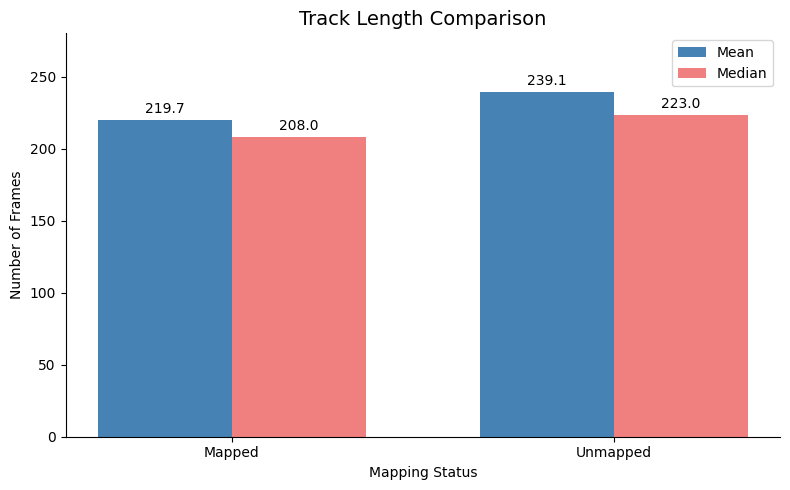

In [26]:
track_comparison = (
    unmapped_lengths
    .groupby("is_mapped")["n_frames"]
    .agg(["mean", "median"])
    .reindex([True, False])
)

labels = ["Mapped", "Unmapped"]
x = np.arange(len(labels))
width = 0.35

fig, ax = plt.subplots(figsize=(8, 5))

bars1 = ax.bar(
    x - width / 2,
    track_comparison["mean"],
    width,
    label="Mean",
    color="steelblue"
)

bars2 = ax.bar(
    x + width / 2,
    track_comparison["median"],
    width,
    label="Median",
    color="lightcoral"
)

# Add value labels
for bars in [bars1, bars2]:
    ax.bar_label(bars, fmt="%.1f", padding=3)

ax.set_title("Track Length Comparison", fontsize=14)
ax.set_xlabel("Mapping Status")
ax.set_ylabel("Number of Frames")
ax.set_xticks(x)
ax.set_xticklabels(labels)
ax.set_ylim(0, 280)
ax.legend()

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

plt.tight_layout()
plt.savefig(PROJECT_DIR / "figures" / "track_length_comparison.png", dpi=150, bbox_inches="tight")
plt.show()


### Track Duration Results

205 of 1,042 SCT tracks (19.7%) have no initial candidate match.

- Initially mapped tracks: mean = 219.7 frames, median = 208 frames.
- Initially unmapped tracks: mean = 239.1 frames, median = 223 frames.

Unmapped tracks are not generally shorter. Cameras 1 and 4 account for 149 of these 205 tracks and have comparatively long trajectories. The next checks examine temporal and spatial overlap with MTMC annotations.

Check temporal overlap between unmapped SCT tracks and MTMC

In [27]:
unmapped_tracks = mapping_check.loc[
    ~mapping_check["is_mapped"],
    ["camera_id", "track_id"]
]

unmapped_obs = sct.merge(
    unmapped_tracks,
    on=["camera_id", "track_id"],
    how="inner",
    validate="many_to_one"
)

mtmc_frames = mtmc[
    ["camera_id", "frame"]
].drop_duplicates()

temporal_check = unmapped_obs.merge(
    mtmc_frames.assign(has_mtmc_frame=True),
    on=["camera_id", "frame"],
    how="left",
    validate="many_to_one"
)

temporal_check["has_mtmc_frame"] = (
    temporal_check["has_mtmc_frame"].eq(True)
)

temporal_summary = (
    temporal_check
    .groupby(["camera_id", "track_id"])
    .agg(
        total_frames=("frame", "nunique"),
        overlapping_frames=("has_mtmc_frame", "sum")
    )
    .reset_index()
)

temporal_summary["overlap_rate"] = (
    temporal_summary["overlapping_frames"] /
    temporal_summary["total_frames"]
)

display(temporal_summary["overlap_rate"].describe())

print(
    "Tracks with no temporal overlap:",
    (temporal_summary["overlapping_frames"] == 0).sum()
)

print(
    "Tracks with temporal overlap:",
    (temporal_summary["overlapping_frames"] > 0).sum()
)

count    205.000000
mean       0.970639
std        0.107625
min        0.000000
25%        1.000000
50%        1.000000
75%        1.000000
max        1.000000
Name: overlap_rate, dtype: float64

Tracks with no temporal overlap: 1
Tracks with temporal overlap: 204


### Temporal Overlap Results

204 of 205 initially unmapped tracks (99.5%) overlap temporally with MTMC annotations. Neither short track duration nor missing temporal overlap appears to be the main reason for unsuccessful matching. The next check compares their bounding boxes.

Spatial Overlap Analysis for Unmapped SCT Tracks

In [28]:
# Find maximum IoU per unmapped track
spatial_summary = (
    pairs.merge(
        unmapped_tracks,
        on=["camera_id", "track_id"],
        how="inner",
        validate="many_to_one"
    )
    .groupby(["camera_id", "track_id"])
    .agg(
        max_iou=("iou", "max"),
        mean_iou=("iou", "mean")
    )
    .reset_index()
)

# Include tracks with no spatial candidates
spatial_summary = unmapped_tracks.merge(
    spatial_summary,
    on=["camera_id", "track_id"],
    how="left",
    validate="one_to_one"
)

spatial_summary["max_iou"] = (
    spatial_summary["max_iou"].fillna(0)
)

display(spatial_summary["max_iou"].describe())

print(
    "Tracks with no candidate pairs:",
    spatial_summary["mean_iou"].isna().sum()
)

print(
    "Tracks with max IoU <= 0.5:",
    (spatial_summary["max_iou"] <= 0.5).sum()
)

print(
    "Tracks with max IoU > 0.5:",
    (spatial_summary["max_iou"] > 0.5).sum()
)

display(
    spatial_summary.groupby("camera_id")["max_iou"]
    .describe()
)

count    205.000000
mean       0.060150
std        0.090117
min        0.000000
25%        0.000000
50%        0.005077
75%        0.094228
max        0.374846
Name: max_iou, dtype: float64

Tracks with no candidate pairs: 1
Tracks with max IoU <= 0.5: 205
Tracks with max IoU > 0.5: 0


,count,mean,std,min,25%,50%,75%,max
camera_id,,,,,,,,
1,83.0,0.047348,0.075270,0.0,0.0,0.000000,0.085043,0.374846
2,22.0,0.044544,0.072264,0.0,0.0,0.002773,0.066235,0.280437
3,34.0,0.086569,0.106824,0.0,0.0,0.052105,0.131141,0.342363
4,66.0,0.067841,0.100711,0.0,0.0,0.009889,0.090951,0.355452


### Spatial Overlap Analysis

Spatial overlap was evaluated for 205 unmapped SCT tracks using bounding-box IoU.

- Mean maximum IoU: 0.060
- Median maximum IoU: 0.005
- Highest observed IoU: 0.375
- All 205 tracks have a maximum IoU below the matching threshold of 0.5.

These tracks do not meet the spatial overlap threshold. This does not establish why the annotations differ. Although 204 tracks have temporal overlap, this does not guarantee that the same vehicles are annotated in MTMC.

The unmapped tracks are retained without global vehicle IDs rather than assigned potentially incorrect matches.

## 8. Vehicle Attribute Consistency

Use accepted matches only to compare vehicle attributes across cameras. Keep the original per-track annotations alongside the standardized values.

In [29]:
accepted_matches = best.loc[
    best["match_status"] == "accepted",
    ["camera_id", "track_id", "vehicle_id"]
]

# Combine global IDs with vehicle attributes
vehicle_attributes = accepted_matches.merge(
    attrs.assign(has_attribute_record=True),
    on=["camera_id", "track_id"],
    how="left",
    validate="one_to_one"
)

vehicle_attributes["has_attribute_record"] = vehicle_attributes["has_attribute_record"].eq(True)

# Count distinct non-missing values per global vehicle
attribute_consistency = (
    vehicle_attributes
    .groupby("vehicle_id")[attribute_cols]
    .nunique(dropna=True)
)

# Identify conflicting attributes
attribute_conflicts = attribute_consistency.gt(1)

print(
    "Vehicles with attribute conflicts:",
    attribute_conflicts.any(axis=1).sum()
)

print("\nConflicts by attribute:")
display(attribute_conflicts.sum().to_frame("conflicts"))

# Show conflicting vehicle annotations
conflicting_ids = attribute_conflicts.index[
    attribute_conflicts.any(axis=1)
]

display(
    vehicle_attributes.loc[
        vehicle_attributes["vehicle_id"].isin(conflicting_ids),
        ["vehicle_id", "camera_id", "track_id"] + attribute_cols
    ].sort_values(["vehicle_id", "camera_id"])
)

Vehicles with attribute conflicts: 21

Conflicts by attribute:


,conflicts
color,10
make,7
model,15
category,3


,vehicle_id,camera_id,track_id,color,make,model,category
5,432,1,52,White,Ford,F-150,Pick Up
181,432,2,3,White,Chevrolet,Silverado,Pick Up
9,433,1,58,Grey,Ford,F-250,Pick Up
179,433,2,1,Grey,Dodge,RAM,Pick Up
74,553,1,225,Silver,Subaru,Outback,SUV and Offroaders
...,...,...,...,...,...,...,...
548,734,3,326,Silver,Lexus,RX450L,SUV and Offroaders
747,734,4,197,Silver,Lexus,RX,SUV and Offroaders
394,744,2,380,Grey,Audi,Q5,SUV and Offroaders
597,744,3,429,Grey,Audi,Q7,SUV and Offroaders


In [30]:
conflict_details = attribute_conflicts.copy()

conflict_details["n_conflicts"] = (
    conflict_details.sum(axis=1)
)

conflict_details = conflict_details[
    conflict_details["n_conflicts"] > 0
].copy()

print("Vehicles with 1 conflicting attribute:",
      (conflict_details["n_conflicts"] == 1).sum())

print("Vehicles with 2 conflicting attributes:",
      (conflict_details["n_conflicts"] == 2).sum())

print("Vehicles with 3+ conflicting attributes:",
      (conflict_details["n_conflicts"] >= 3).sum())

display(
    conflict_details.sort_values(
        "n_conflicts", ascending=False
    )
)


Vehicles with 1 conflicting attribute: 13
Vehicles with 2 conflicting attributes: 4
Vehicles with 3+ conflicting attributes: 4


,color,make,model,category,n_conflicts
vehicle_id,,,,,
644,True,True,True,True,4
553,True,True,True,True,4
593,True,True,True,False,3
677,False,True,True,True,3
432,False,True,True,False,2
705,True,False,True,False,2
433,False,True,True,False,2
666,False,True,True,False,2
649,True,False,False,False,1


## 9. Attribute Conflict Resolution

Keep an attribute when its non-missing annotations agree. Leave conflicting values missing and retain a conflict flag. No vehicles are removed.

In [31]:
def resolve_attribute(series):
    values = series.dropna().unique()

    if len(values) == 1:
        return values[0]
    return pd.NA

# Create one attribute record per global vehicle
resolved_attrs = (
    vehicle_attributes
    .groupby("vehicle_id")[attribute_cols]
    .agg(resolve_attribute)
    .reset_index()
)

# Add conflict flags
conflict_flags = (
    attribute_conflicts
    .add_prefix("conflict_")
    .reset_index()
)

resolved_attrs = resolved_attrs.merge(
    conflict_flags,
    on="vehicle_id",
    how="left",
    validate="one_to_one"
)

resolved_attrs["has_conflict"] = (
    resolved_attrs[
        [f"conflict_{col}" for col in attribute_cols]
    ].any(axis=1)
)

resolved_attrs = resolved_attrs.merge(
    vehicle_attributes.groupby("vehicle_id")["has_attribute_record"].any().reset_index(),
    on="vehicle_id",
    validate="one_to_one"
)

print("Vehicles:", len(resolved_attrs))
print("Vehicles with conflicts:",
      resolved_attrs["has_conflict"].sum())

display(
    resolved_attrs[
        resolved_attrs["has_conflict"]
    ].head(10)
)

Vehicles: 311
Vehicles with conflicts: 21


,vehicle_id,color,make,model,category,conflict_color,conflict_make,conflict_model,conflict_category,has_conflict,has_attribute_record
128,432,White,<NA>,<NA>,Pick Up,False,True,True,False,True,True
129,433,Grey,<NA>,<NA>,Pick Up,False,True,True,False,True,True
171,553,<NA>,<NA>,<NA>,<NA>,True,True,True,True,True,True
185,587,Black,Ford,<NA>,SUV and Offroaders,False,False,True,False,True,True
189,593,<NA>,<NA>,<NA>,Heavy Duty Trucks,True,True,True,False,True,True
190,595,<NA>,Ford,Transit,Commercial Van,True,False,False,False,True,True
192,600,<NA>,Chevrolet,Silverado,Pick Up,True,False,False,False,True,True
210,644,<NA>,<NA>,<NA>,<NA>,True,True,True,True,True,True
215,649,<NA>,Ford,Mondeo,Small Passenger Vehicles,True,False,False,False,True,True
219,653,Red,Concrete,<NA>,Heavy Duty Trucks,False,False,True,False,True,True


## 10. Final Data Integration

Attach confirmed global IDs to accepted SCT tracks only. Keep review and unmapped observations, and use resolved attributes for MTMC.

In [32]:
final_track_map = accepted_matches.copy()

# Integrate SCT observations without confirming review matches.
sct_clean = (
    sct.merge(
        attrs.assign(has_attribute_record=True),
        on=["camera_id", "track_id"],
        how="left",
        validate="many_to_one"
    )
    .merge(
        final_track_map,
        on=["camera_id", "track_id"],
        how="left",
        validate="many_to_one"
    )
    .merge(
        mapping_check[["camera_id", "track_id", "match_status", "mapping_conflict", "review_reason"]],
        on=["camera_id", "track_id"],
        how="left",
        validate="many_to_one"
    )
)
sct_clean["vehicle_id"] = sct_clean["vehicle_id"].astype("Int64")
sct_clean["has_attribute_record"] = sct_clean["has_attribute_record"].eq(True)

# Integrate resolved attributes into MTMC.
mtmc_clean = mtmc.merge(
    resolved_attrs,
    on="vehicle_id",
    how="left",
    validate="many_to_one"
)
mtmc_clean["has_attribute_record"] = mtmc_clean["has_attribute_record"].eq(True)

print("SCT observations:", len(sct_clean))
print("MTMC observations:", len(mtmc_clean))
print(
    "SCT tracks without accepted global ID:",
    sct_clean.loc[sct_clean["vehicle_id"].isna(), ["camera_id", "track_id"]]
    .drop_duplicates().shape[0]
)

SCT observations: 232919
MTMC observations: 177756
SCT tracks without accepted global ID: 210


## 11. Final Data Validation

Check row preservation, unique observation keys and valid mapping relationships. Separate missing annotation records from attributes left unresolved because of conflicts.

In [33]:
print("Duplicate SCT observations:",
      sct_clean.duplicated(["camera_id", "track_id", "frame"]).sum())
print("Duplicate MTMC observations:",
      mtmc_clean.duplicated(["camera_id", "vehicle_id", "frame"]).sum())
print("Duplicate resolved vehicle IDs:", resolved_attrs.duplicated("vehicle_id").sum())
print("SCT observations without an accepted global ID:", sct_clean["vehicle_id"].isna().sum())
print("MTMC vehicles:", mtmc_clean["vehicle_id"].nunique())

assert len(sct_clean) == len(sct)
assert len(mtmc_clean) == len(mtmc)
assert not sct_clean.duplicated(["camera_id", "track_id", "frame"]).any()
assert not mtmc_clean.duplicated(["camera_id", "vehicle_id", "frame"]).any()
assert not resolved_attrs.duplicated("vehicle_id").any()
assert not final_track_map.duplicated(["camera_id", "track_id"]).any()
assert not sct_clean.loc[sct_clean["vehicle_id"].notna()].duplicated(
    ["camera_id", "vehicle_id", "frame"]
).any()
assert sct_clean["vehicle_id"].notna().equals(sct_clean["match_status"].eq("accepted"))

mapping_validation = final_track_map.merge(
    mtmc[["camera_id", "vehicle_id"]].drop_duplicates(),
    on=["camera_id", "vehicle_id"],
    how="left",
    indicator=True,
    validate="many_to_one"
)
assert mapping_validation["_merge"].eq("both").all()

for table in [sct_clean, mtmc_clean]:
    assert np.isfinite(table[["x", "y", "width", "height"]]).all().all()
    assert ((table["x"] >= 0) & (table["y"] >= 0) &
            (table["width"] > 0) & (table["height"] > 0) &
            (table["x"] + table["width"] <= IMG_W) &
            (table["y"] + table["height"] <= IMG_H)).all()

print("Row preservation, unique keys, mapping and bounding box checks passed.")

Duplicate SCT observations: 0
Duplicate MTMC observations: 0
Duplicate resolved vehicle IDs: 0
SCT observations without an accepted global ID: 50048
MTMC vehicles: 311


Row preservation, unique keys, mapping and bounding box checks passed.


In [34]:
attribute_check = mtmc[["vehicle_id"]].drop_duplicates().merge(
    resolved_attrs,
    on="vehicle_id",
    how="left",
    indicator=True,
    validate="one_to_one"
)
no_attribute_record = attribute_check["_merge"].eq("left_only")
has_annotations = attribute_check["has_attribute_record"].eq(True)

print("MTMC vehicles:", len(attribute_check))
print("Without resolved attribute record:", no_attribute_record.sum())
print("Without source attribute annotations:", (~has_annotations).sum())

missing_attributes = []
for col in attribute_cols:
    missing = attribute_check[col].isna()
    conflict = attribute_check[f"conflict_{col}"].eq(True)
    assert attribute_check.loc[conflict, col].isna().all()
    missing_attributes.append({
        "attribute": col,
        "missing_vehicles": missing.sum(),
        "unresolved_conflict": (missing & conflict).sum(),
        "no_annotation_record": (missing & ~has_annotations).sum(),
        "missing_in_annotations": (missing & has_annotations & ~conflict).sum()
    })
display(pd.DataFrame(missing_attributes).set_index("attribute"))

print("Vehicles with missing make:")
display(attribute_check.loc[
    attribute_check["make"].isna(),
    ["vehicle_id"] + attribute_cols + ["conflict_make", "has_attribute_record", "_merge"]
])

MTMC vehicles: 311
Without resolved attribute record: 0
Without source attribute annotations: 0


,missing_vehicles,unresolved_conflict,no_annotation_record,missing_in_annotations
attribute,,,,
color,10,10,0,0
make,7,7,0,0
model,15,15,0,0
category,3,3,0,0


Vehicles with missing make:


,vehicle_id,color,make,model,category,conflict_make,has_attribute_record,_merge
5,432,White,<NA>,<NA>,Pick Up,True,True,both
9,433,Grey,<NA>,<NA>,Pick Up,True,True,both
36,666,Black,<NA>,<NA>,Pick Up,True,True,both
50,644,<NA>,<NA>,<NA>,<NA>,True,True,both
56,593,<NA>,<NA>,<NA>,Heavy Duty Trucks,True,True,both
74,553,<NA>,<NA>,<NA>,<NA>,True,True,both
159,677,White,<NA>,<NA>,<NA>,True,True,both


### Final Vehicle Attribute Validation

All 311 MTMC vehicles have corresponding records in the resolved attribute table.

Missing or unresolved attributes:
- Color: 10 vehicles (3.2%)
- Make: 7 vehicles (2.3%)
- Model: 15 vehicles (4.8%)
- Category: 3 vehicles (1.0%)

These missing values result from previously identified annotation conflicts. Conflicting attributes were intentionally set to missing to avoid introducing potentially incorrect information.

No vehicles were removed during attribute conflict resolution.


## 12. Export & Export Validation

Export the final tables and read them back to check their size and columns. In `track_mapping_quality.csv`, vehicle IDs for `review` rows are candidate IDs, not confirmed matches.

In [35]:
OUT_DIR.mkdir(parents=True, exist_ok=True)

sct_clean.to_csv(OUT_DIR / "sct_clean.csv", index=False)
mtmc_clean.to_csv(OUT_DIR / "mtmc_clean.csv", index=False)
resolved_attrs.to_csv(OUT_DIR / "vehicle_attributes_resolved.csv", index=False)
best.to_csv(OUT_DIR / "track_mapping_quality.csv", index=False)

print("All cleaned datasets exported successfully.")

All cleaned datasets exported successfully.


In [36]:
for filename, expected in [
    ("sct_clean.csv", sct_clean),
    ("mtmc_clean.csv", mtmc_clean),
    ("vehicle_attributes_resolved.csv", resolved_attrs),
    ("track_mapping_quality.csv", best)
]:
    path = OUT_DIR / filename
    assert path.is_file()
    df_check = pd.read_csv(path, low_memory=False)
    assert len(df_check) == len(expected)
    assert df_check.columns.tolist() == expected.columns.tolist()
    print(f"{filename}: {len(df_check):,} rows, {len(df_check.columns)} columns")

sct_clean.csv: 232,919 rows, 24 columns
mtmc_clean.csv: 177,756 rows, 17 columns
vehicle_attributes_resolved.csv: 311 rows, 11 columns
track_mapping_quality.csv: 837 rows, 11 columns
